# Aprendizado Supervisionado no Neurônio Perceptron

## Trabalho Redes Neurais 2.1
### Dupla:

1. Izabella de Lima Catrinck - 2315310033

2. Vinícius Castro Coutinho - 2315310039

In [190]:
import numpy as np
import random
import os
from pathlib import Path
import io
import matplotlib.pyplot as plt
from contextlib import redirect_stdout
from prettytable import PrettyTable
from sklearn import metrics
random.seed()

# Parte I – Resolvendo um Problema Linearmente Separável

In [ ]:
npfile = Path("data/dataAll20262.npy")
if not npfile.exists():
  os.rename("data/dataAll20262.txt", "data/dataAll20262.npy")

input_array = np.load(npfile)
input_array.view()

array([[[ 547.91209711, -122.2431205 ,    1.        ]],

       [[ 717.19583982,  394.73605812,    0.        ]],

       [[-811.64530422,  951.24470327,    0.        ]],

       ...,

       [[ -49.38876423,  507.54135929,    0.        ]],

       [[-429.75519917, -329.90624499,    1.        ]],

       [[ 691.39880129,   40.14382452,    1.        ]]])

In [421]:
class Neuron:
  def __init__(
      self, learning_rate=0.1, threshold=0, initial_weights_interval=(-0.5, 0.5001),
      use_bias=False
    ):
    self.learning_rate = learning_rate
    self.threshold = threshold
    self.use_bias = use_bias
    self.epoch = 0
    self.weight_adjustments = 0
    # Sem bias: pesos [w1, w2]. Com bias: pesos [w1, w2, bias]
    self.weights = np.random.uniform(
        low=initial_weights_interval[0], high=initial_weights_interval[1],
        size=3 if use_bias else 2
      )

    if use_bias:
      print(f"Vetor inicial de pesos (w1, w2, bias):\n{self.weights}")
    else:
      print(f"Vetor inicial de pesos:\n{self.weights}")

  def step_activation_function(self, x_weighted_sum):
    if x_weighted_sum >= self.threshold:
      return 1
    else:
      return 0

  def inputs(self, x: np.ndarray):
    """Entradas do exemplo; com bias, acrescenta a entrada fixa 1"""
    if self.use_bias:
      return np.array([x[0], x[1], 1.0])
    return x[:2]

  def weighted_sum(self, x: np.ndarray):
    return np.dot(self.weights, self.inputs(x))

  def calculate_error(self, predicted_y: int, x:np.ndarray):
    return x[2] - predicted_y

  def check_convergence(self, array):
    for x in array[0:, 0]:
        u = self.weighted_sum(x)

        predicted_y = self.step_activation_function(u)

        error = self.calculate_error(predicted_y, x)

        if error:
          print("Não convergiu")
          return False
    print("Convergiu")
    return True

  def train_to_convergence(self, input_array):
    running = True
    while running:
      running = False

      self.epoch += 1
      for x in input_array[0:, 0]:
        u = self.weighted_sum(x)

        predicted_y = self.step_activation_function(u)

        error = self.calculate_error(predicted_y, x)

        if error:
          running = True
          self.weight_adjustments += 1
          self.weights += (error * self.learning_rate * self.inputs(x))

    print(f"Número de épocas: {self.epoch}")
    print(f"Número de ajustes nos pesos: {self.weight_adjustments}")
    self.graph(input_array)

  def train(self, input_array):
    """Trains neuron for 01 epoch"""
    self.epoch += 1
    for x in input_array[0:, 0]:
      u = self.weighted_sum(x)

      predicted_y = self.step_activation_function(u)

      error = self.calculate_error(predicted_y, x)

      if error:
        self.weight_adjustments += 1
        self.weights += (error * self.learning_rate * self.inputs(x))

  def predict(self, test_array):
    """Return a 1D array of predicted y values"""
    prediction = np.array([])
    for example in test_array[0:, 0]:
      u = self.weighted_sum(example)

      predicted_y = self.step_activation_function(u)

      prediction = np.append(prediction, predicted_y)
    return prediction

  def graph(self, input_array):
    examples = input_array[:, 0, :]
    class_zero = examples[:, 2] == 0
    class_one = examples[:, 2] == 1
    bias = self.weights[2] if self.use_bias else 0

    plt.figure(figsize=(9, 6))
    plt.scatter(
        examples[class_zero, 0], examples[class_zero, 1],
        color="red", label="Classe 0", alpha=0.75, edgecolors="white"
      )
    plt.scatter(
        examples[class_one, 0], examples[class_one, 1],
        color="blue", label="Classe 1", alpha=0.75, edgecolors="white"
      )

    if abs(self.weights[1]) > np.finfo(float).eps:
      x_values = np.array([examples[:, 0].min(), examples[:, 0].max()])
      y_values = (self.threshold - bias - self.weights[0] * x_values) / self.weights[1]
      plt.plot(x_values, y_values, color="black", linewidth=2,
                label="Fronteira de decisão")
    elif abs(self.weights[0]) > np.finfo(float).eps:
      x_boundary = (self.threshold - bias) / self.weights[0]
      plt.axvline(x_boundary, color="black", linewidth=2,
                  label="Fronteira de decisão")

    plt.title(f"Classificação pelo Perceptron após {self.epoch} épocas")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.grid(True, alpha=0.25)
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
    plt.tight_layout()
    plt.show()

  def graph_train_test(self, train_array, test_array):
    fig, axes = plt.subplots(ncols=2, figsize=(14, 8))

    for ax, ax_type in zip(axes, ["train", "test"]):
      examples = train_array[:, 0, :] if ax_type == "train" else test_array[:, 0, :]
      class_zero = examples[:, 2] == 0
      class_one = examples[:, 2] == 1
      bias = self.weights[2] if self.use_bias else 0

      ax.scatter(
          examples[class_zero, 0], examples[class_zero, 1],
          color="red", label="Classe 0", alpha=0.75, edgecolors="white"
        )
      ax.scatter(
          examples[class_one, 0], examples[class_one, 1],
          color="blue", label="Classe 1", alpha=0.75, edgecolors="white"
        )

      if abs(self.weights[1]) > np.finfo(float).eps:
        x_values = np.array([examples[:, 0].min(), examples[:, 0].max()])
        y_values = (self.threshold - bias - self.weights[0] * x_values) / self.weights[1]
        ax.plot(x_values, y_values, color="black", linewidth=2,
                  label="Fronteira de decisão")
      elif abs(self.weights[0]) > np.finfo(float).eps:
        x_boundary = (self.threshold - bias) / self.weights[0]
        ax.axvline(x_boundary, color="black", linewidth=2,
                    label="Fronteira de decisão")

      if ax_type == "train":
        ax.set_title(f"Training array")
      else:
        ax.set_title(f"Test array")
      ax.set_xlabel("x1")
      ax.set_ylabel("x2")
      ax.legend()
      ax.grid(True, alpha=0.25)

    return fig, axes

Vetor inicial de pesos:
[ 0.49443665 -0.49099943]
Número de épocas:3
Número de ajustes nos pesos:42


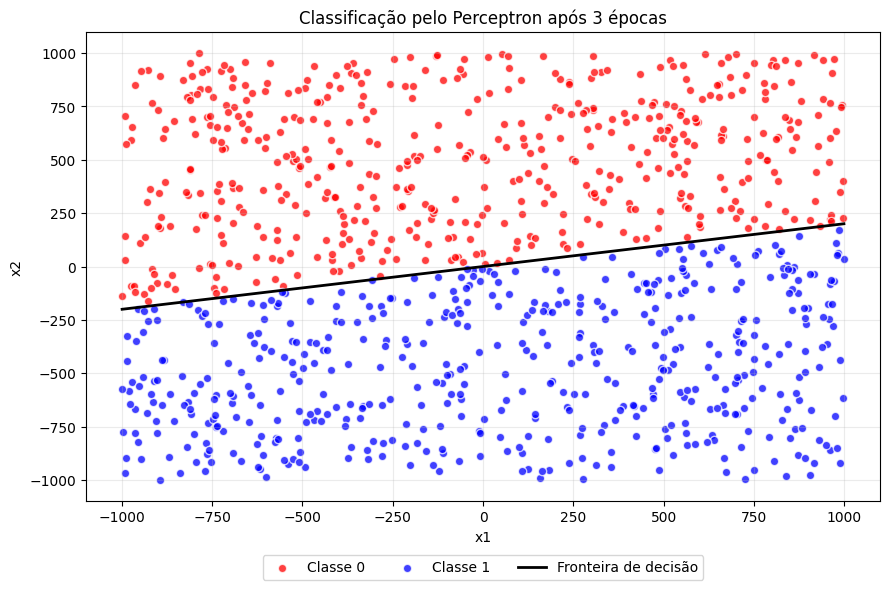

In [ ]:
neuronio = Neuron()
neuronio.train_to_convergence(input_array)

# Parte II – Experimentação

In [ ]:
team_id = (3 + 9) % 4

npfile = Path(f"data/data{team_id}20262.npy")
if not npfile.exists():
  os.rename(f"data/data{team_id}20262.txt", npfile)

team_array = np.load(npfile)

mu = team_array[:, 0, :2].mean(axis=0)
sigma = team_array[:, 0, :2].std(axis=0)

team_scaled = team_array.copy()
team_scaled[:, 0, :2] = (team_array[:, 0, :2] - mu) / sigma

In [ ]:
learning_rates = [0.4, 0.1, 0.01]
intervals = [(-100, 100), (-0.5, 0.5)]
REPETITIONS = 10
MAX_EPOCHS = 5000

def run_once(data, learning_rate, interval):
  with redirect_stdout(io.StringIO()):
    neuron = Neuron(learning_rate=learning_rate, initial_weights_interval=interval, use_bias=True)

  for _ in range(MAX_EPOCHS):
    adjustments_before = neuron.weight_adjustments
    neuron.train(data)  # treina 1 época

    if neuron.weight_adjustments == adjustments_before:
      return neuron.weight_adjustments, neuron.epoch, True

  return neuron.weight_adjustments, neuron.epoch, False

In [ ]:
results = {}

for lr in learning_rates:
  for interval in intervals:
    adjustments = []
    epochs = []

    for _ in range(REPETITIONS):
      total_adjustments, total_epochs, converged = run_once(team_scaled, lr, interval)

      if not converged:
        print(f"Atenção: não convergiu em {MAX_EPOCHS} épocas (η={lr}, I={interval})")

      adjustments.append(total_adjustments)
      epochs.append(total_epochs)

    results[(lr, interval)] = {"adjustments": adjustments, "epochs": epochs}

print("Experimentos finalizados.")

Experimentos finalizados.


In [ ]:
table = PrettyTable()
table.field_names = [
    "Taxa de Aprendizado", "Intervalo de Pesos", "Qtde Ajustes", "Min Épocas", "Max Épocas"
]

for (lr, interval), r in results.items():
  table.add_row([
      f"η = {lr}",
      f"({interval[0]}, +{interval[1]})",
      f"{np.mean(r['adjustments']):.2f} ± {np.std(r['adjustments']):.2f}",
      min(r["epochs"]),
      max(r["epochs"]),
  ])

print(table)

+---------------------+--------------------+-------------------+------------+------------+
| Taxa de Aprendizado | Intervalo de Pesos |    Qtde Ajustes   | Min Épocas | Max Épocas |
+---------------------+--------------------+-------------------+------------+------------+
|       η = 0.4       |    (-100, +100)    |  466.30 ± 203.21  |     7      |    135     |
|       η = 0.4       |    (-0.5, +0.5)    |  1434.40 ± 924.49 |     11     |    480     |
|       η = 0.1       |    (-100, +100)    |  947.60 ± 475.63  |     9      |    126     |
|       η = 0.1       |    (-0.5, +0.5)    |  562.30 ± 515.84  |     14     |    207     |
|       η = 0.01      |    (-100, +100)    | 7862.00 ± 3867.53 |     32     |    210     |
|       η = 0.01      |    (-0.5, +0.5)    |  1214.80 ± 779.29 |     6      |    449     |
+---------------------+--------------------+-------------------+------------+------------+


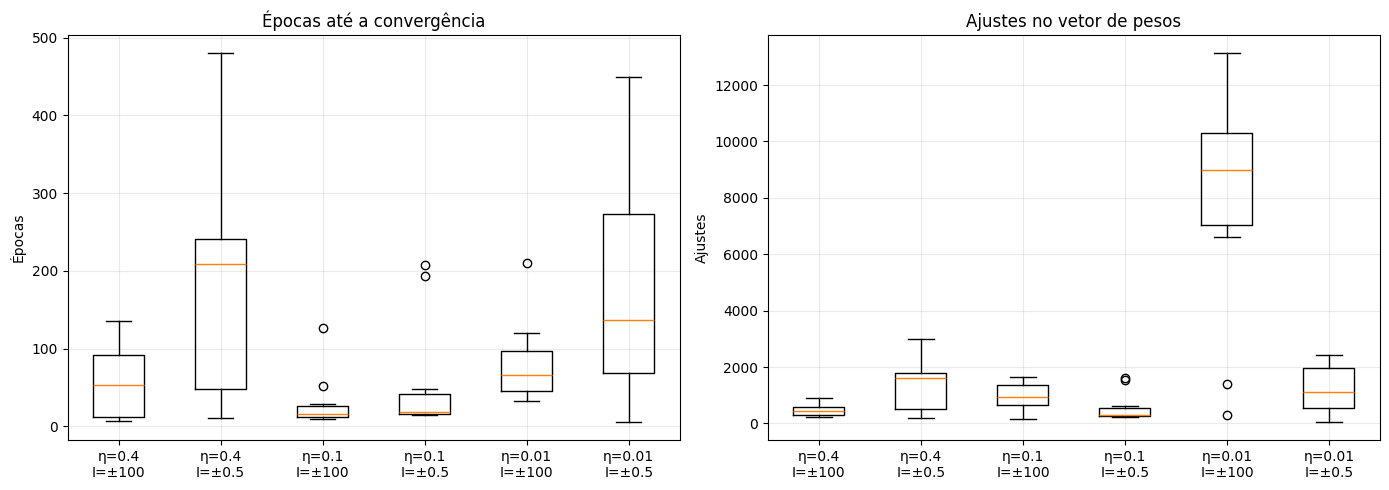

In [ ]:
labels = [f"η={lr}\nI=±{interval[1]}" for (lr, interval) in results]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].boxplot([r["epochs"] for r in results.values()], tick_labels=labels)
axes[0].set_title("Épocas até a convergência")
axes[0].set_ylabel("Épocas")
axes[0].grid(True, alpha=0.25)

axes[1].boxplot([r["adjustments"] for r in results.values()], tick_labels=labels)
axes[1].set_title("Ajustes no vetor de pesos")
axes[1].set_ylabel("Ajustes")
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

Existe uma configuração melhor que as demais: η = 0.1 e intervalo de (-100 a +100).  
De acordo com os boxplots, o treinamento foi realizado no menor número de épocas em média entre as configurações, com apenas dois outliers, os quais ainda foram menores que o número de épocas máximas das outras. Apesar disso, o número de épocas ainda está na mesma ordem de grandeza em todas as configurações, então não é seguro dizer que essa configuração foi consideravelmente superior às outras.

Tratando-se de ajustes no vetor de pesos, essa configuração não foi a melhor, lugar que foi reservado para a configuração η = 0.4 e intervalo (-100 a +100), mas ainda assim esteve na mesma ordem de grandeza. Entretanto, uma configuração destaca-se das outras por ter a quantidade de ajustes consideravelmente maior que as outras: {0.01, (-100, +100)}, com 25% das quantidades maior que 10.000. Essa, então, foi a pior configuração no aspecto quantidade de ajustes.


# Parte III - Validação *Holdout* em Problema Não-Linearmente Separável

In [422]:
npfile = Path(f"data/dataHoldout20262.npy")
if not npfile.exists():
  os.rename(f"data/dataHoldout20262.txt", npfile)

array = np.load(npfile)
SEED = team_id
rng = np.random.default_rng(seed=SEED)

# Holdout array doesn't have the same shape as the other arrays we've seen so far
print(f"Holdout array shape: {array.shape}\nPrevious arrays shape: {input_array.shape}")
print("Converting holdout array shape to accepted shape...")
holdout_array = np.array([[example] for example in array])
print(f"Holdout array shape: {holdout_array.shape}\nPrevious arrays shape: {input_array.shape}")
print("Done!")

Holdout array shape: (1000, 3)
Previous arrays shape: (1000, 1, 3)
Converting holdout array shape to accepted shape...
Holdout array shape: (1000, 1, 3)
Previous arrays shape: (1000, 1, 3)
Done!


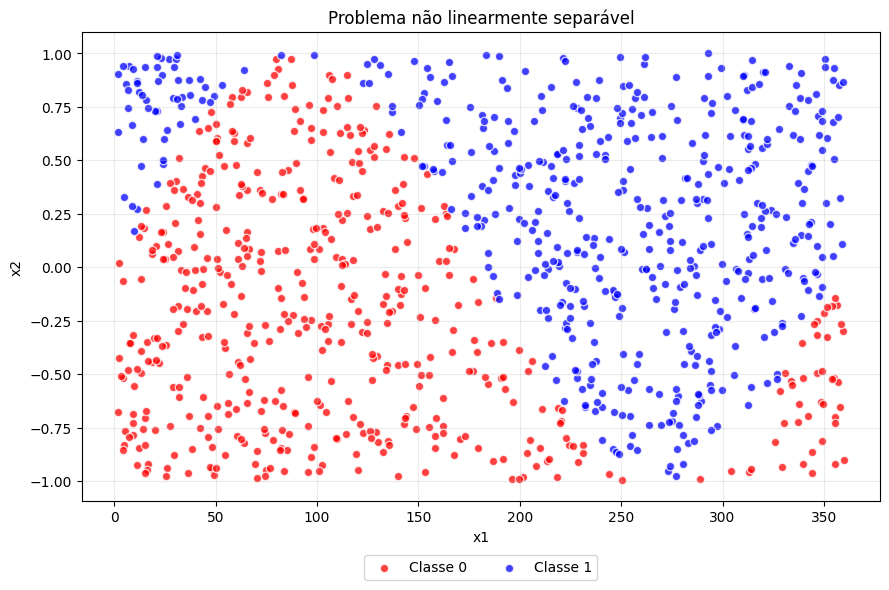

In [423]:
def graph(input_array):
  examples = input_array[:, 0, :]
  class_zero = examples[:, 2] == 0
  class_one = examples[:, 2] == 1

  plt.figure(figsize=(9, 6))
  plt.scatter(
      examples[class_zero, 0], examples[class_zero, 1],
      color="red", label="Classe 0", alpha=0.75, edgecolors="white"
    )
  plt.scatter(
      examples[class_one, 0], examples[class_one, 1],
      color="blue", label="Classe 1", alpha=0.75, edgecolors="white"
    )

  plt.title(f"Problema não linearmente separável")
  plt.xlabel("x1")
  plt.ylabel("x2")
  plt.grid(True, alpha=0.25)
  plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
  plt.tight_layout()
  plt.show()

graph(holdout_array)

In [424]:
# shuffling the array
previous_array = np.copy(holdout_array)
rng.shuffle(holdout_array)
assert not np.array_equal(holdout_array, previous_array), "Holdout array wasn't randomized"

In [425]:
# Splitting in training and test arrays
seventy_percent = round(holdout_array.shape[0] * 0.7)

split_array = np.split(holdout_array, indices_or_sections=[seventy_percent])

training = split_array[0]

test = split_array[1]

print(f"Training array shape: {training.shape}\nTest array shape: {test.shape}")

Training array shape: (700, 1, 3)
Test array shape: (300, 1, 3)


In [426]:
# Training
neuron3 = Neuron()

for _ in range(100):
  neuron3.train(training)

Vetor inicial de pesos:
[ 0.10076886 -0.38950253]


In [427]:
prediction = neuron3.predict(test)

In [428]:
# for confusion matrix to work, y_true must be a 1D array
true_values = [example[2] for example in test[0:, 0]]

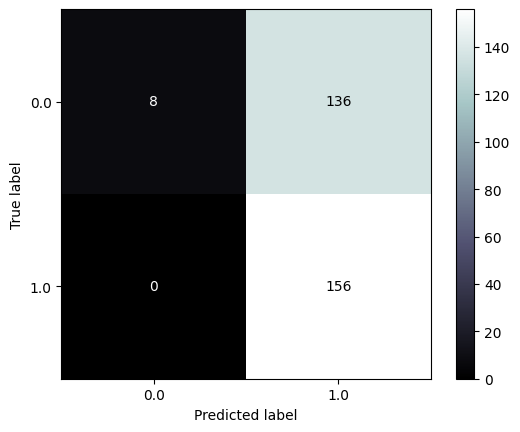

In [429]:
confusion_matrix = metrics.ConfusionMatrixDisplay.from_predictions(
    y_true=true_values,
    y_pred=prediction,
    cmap="bone",
)

In [430]:
accuracy = round(((8 + 156) / 300) * 100, 2)

# F1-Score
f1_score = metrics.f1_score(
    y_true=true_values,
    y_pred=prediction,
)
f1_score = round(f1_score * 100, 2)

# Precisão
precision = metrics.precision_score(
    y_true=true_values,
    y_pred=prediction,
)
precision = round(precision * 100, 2)

# Recall
recall = metrics.recall_score(
    y_true=true_values,
    y_pred=prediction,
)
recall = round(recall * 100, 2)

print(f"Acurácia: {accuracy}%")
print(f"Precisão: {precision}%")
print(f"Recall: {recall}%")
print(f"F1-Score: {f1_score}%\n")

Acurácia: 54.67%
Precisão: 53.42%
Recall: 100.0%
F1-Score: 69.64%



Essa solução foi muito boa para uma só classe, que foi a positiva, e foi completamente terrível para a outra classe, acertando quase nenhuma predição. Em outras palavras, o modelo respondeu apenas a classe positiva pra qualquer exemplo, salvo 8 exceções. Logo, esse modelo é péssimo.

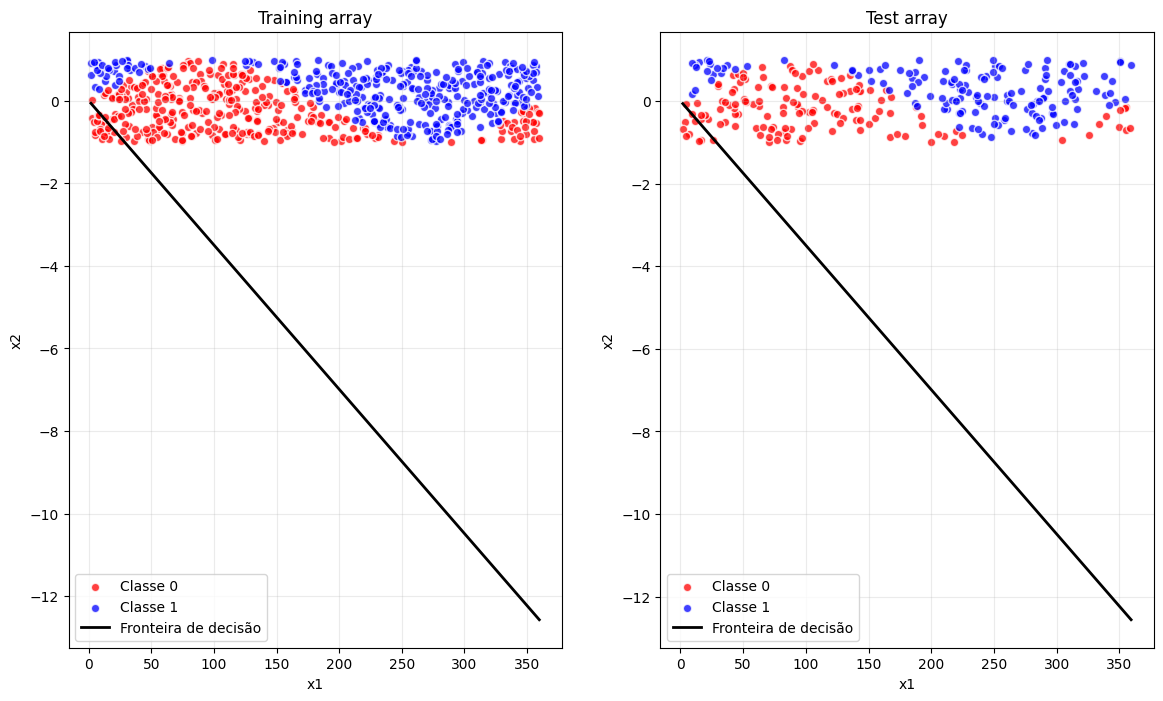

In [431]:
fig, ax_train = neuron3.graph_train_test(training, test)